# A/B Testing of Machine Learning Models: Model A vs Model B

**Author:** Luke Wamalwa

## Introduction

A team runs a production model (**Model A**) and has trained a candidate (**Model B**) that looks better on offline validation data. Before switching, they want to know whether B is better *for live traffic*:

- Does Model B produce **more accurate predictions**?
- Is it **faster or slower** to respond?
- Are the differences large enough to matter, and how sure can we be?

This notebook walks through that A/B test end to end, in the order it should happen in practice:

1. **Design before data:** choose metrics, significance level and the smallest effect worth detecting, then compute the sample size.
2. **Collect** prediction logs with requests randomly routed to A or B.
3. **Sanity-check** the randomisation (sample ratio mismatch).
4. **Analyse once,** reporting effect sizes with 95% confidence intervals, not just p-values.
5. **Correct for testing two metrics** (Holm).
6. Show **why peeking** at the results early breaks the error rate.

> **The data is simulated.** Model B is built to be 92% accurate vs 85% for A, and about 10% faster. The analysis can only recover what was put in. The point is the procedure, which is reusable on real logs. The statistics live in the small, unit-tested package `src/abtest/` so the same code can be pointed at real data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from abtest import (
    compare_continuous,
    compare_proportions,
    holm,
    peeking_false_positive_rate,
    power_two_proportions,
    cohens_h,
    sample_size_two_proportions,
    simulate_ab_test_data,
    srm_check,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, PLOTS = ROOT / "data", ROOT / "plots"
DATA.mkdir(exist_ok=True)
PLOTS.mkdir(exist_ok=True)

## 1. Design the test before collecting data

**Metrics (fixed in advance):**

- *Accuracy* (share of correct predictions). The two classes are balanced in this traffic, so accuracy is a reasonable headline metric here. On imbalanced problems you would use precision/recall or a cost-weighted metric instead.
- *Latency* in milliseconds, a guardrail: B must not be meaningfully slower.

**Error rates:** two-sided tests, family-wise α = 0.05 across the two metrics (Holm correction). For planning we use the conservative per-test α = 0.025, and 80% power.

**Smallest effect worth detecting:** an accuracy gain from 85% to 90% (5 percentage points). Smaller gains would not justify the cost of a migration.

The sample size follows from these choices, **not** from the data. Power is a property of the design: it is computed here, for an assumed effect. Calculating "observed power" from the effect seen after the test is a known fallacy (it is just a restatement of the p-value).

In [2]:
ALPHA_FAMILY = 0.05
ALPHA_PER_TEST = ALPHA_FAMILY / 2      # conservative planning value for 2 metrics
POWER = 0.80
BASELINE, TARGET = 0.85, 0.90

n_per_group = sample_size_two_proportions(BASELINE, TARGET, alpha=ALPHA_PER_TEST, power=POWER)
print(f"Cohen's h for 85% -> 90%: {cohens_h(TARGET, BASELINE):.3f}")
print(f"Required per group: {n_per_group}  (total {2 * n_per_group})")

# 50/50 random routing gives slightly unequal groups, so add a small margin.
N_TOTAL = 1700
print(f"Planned total requests: {N_TOTAL}")

Cohen's h for 85% -> 90%: 0.152
Required per group: 824  (total 1648)
Planned total requests: 1700


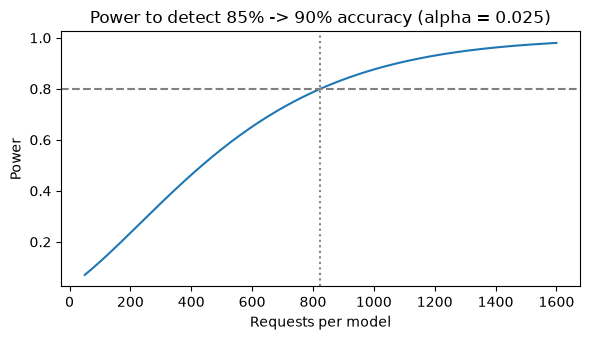

In [3]:
# Power curve: how the chance of detecting a 5-point gain grows with sample size.
h = cohens_h(TARGET, BASELINE)
ns = np.arange(50, 1601, 10)
plt.figure(figsize=(6, 3.5))
plt.plot(ns, [power_two_proportions(h, n, ALPHA_PER_TEST) for n in ns])
plt.axhline(POWER, ls="--", c="grey")
plt.axvline(n_per_group, ls=":", c="grey")
plt.xlabel("Requests per model")
plt.ylabel("Power")
plt.title("Power to detect 85% -> 90% accuracy (alpha = 0.025)")
plt.tight_layout()
plt.savefig(PLOTS / "power_curve.png", dpi=120)
plt.show()

## 2. Collect the data (simulated)

`simulate_ab_test_data()` routes each request to A or B at random and logs:

- `model_version`, `true_label`, `prediction`, `success` (prediction correct?)
- `latency_ms`: drawn from a **log-normal** distribution (median 110 ms for A, 100 ms for B). Real service latency is right-skewed with a long tail, which matters for the choice of test below.
- `user_id` and `timestamp`

The seed and start time are fixed, so the notebook reproduces exactly. The log is written to `data/ab_model_predictions.csv`.

In [4]:
df = simulate_ab_test_data(n=N_TOTAL, seed=42)
df.to_csv(DATA / "ab_model_predictions.csv", index=False)
df.head()

,request_id,user_id,model_version,prediction,true_label,success,latency_ms,timestamp
0,0,3901,A,1,0,False,139.0,2025-05-07 17:00:00
1,1,8514,B,1,0,False,131.4,2025-05-07 17:00:01
2,2,1699,B,1,1,True,108.9,2025-05-07 17:00:02
3,3,9063,A,0,0,True,131.1,2025-05-07 17:00:03
4,4,7975,A,1,1,True,112.1,2025-05-07 17:00:04


## 3. Sanity check: sample ratio mismatch

If routing is 50/50, the group sizes should be close to equal. A very small p-value here (a common threshold is < 0.001) would mean randomisation or logging is broken, and nothing downstream could be trusted.

In [5]:
counts = df["model_version"].value_counts().sort_index()
print(counts.to_string())
print(f"SRM chi-square p-value: {srm_check(counts['A'], counts['B']):.3f}")

model_version
A    838
B    862
SRM chi-square p-value: 0.561


## 4. Accuracy: two-proportion test with a confidence interval

Accuracy per model is a proportion, so we compare two proportions. The pooled two-proportion z-test is the same test as a chi-square test of independence on the 2×2 table (model × correct), without continuity correction.

We report, in order of importance:

1. the **difference** in accuracy (B − A) with a 95% confidence interval (Newcombe/Wilson method),
2. **Cohen's h** as a scale-free effect size,
3. the p-value.

In [6]:
acc = df.groupby("model_version")["success"].agg(["sum", "count"])
r_acc = compare_proportions(
    acc.loc["A", "sum"], acc.loc["A", "count"], acc.loc["B", "sum"], acc.loc["B", "count"]
)
print(f"Accuracy A: {r_acc.rate_a:.3f}   Accuracy B: {r_acc.rate_b:.3f}")
print(f"Difference (B - A): {100 * r_acc.diff:+.1f} pp, 95% CI [{100 * r_acc.ci_low:+.1f}, {100 * r_acc.ci_high:+.1f}] pp")
print(f"Cohen's h: {r_acc.cohens_h:.3f}")
print(f"z = {r_acc.z:.2f}, p = {r_acc.p_value:.2g}")

Accuracy A: 0.863   Accuracy B: 0.907
Difference (B - A): +4.4 pp, 95% CI [+1.4, +7.5] pp
Cohen's h: 0.140
z = 2.87, p = 0.0041


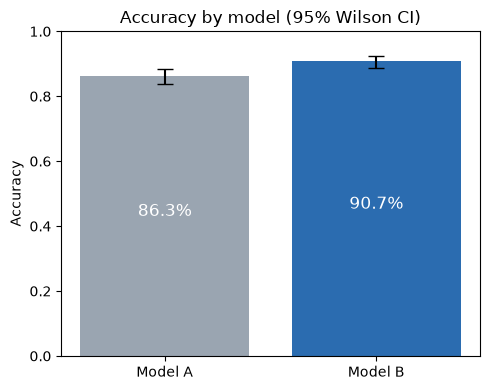

In [7]:
from scipy.stats import norm

z = norm.ppf(0.975)
rates = np.array([r_acc.rate_a, r_acc.rate_b])
ns_ = acc["count"].to_numpy()
# Wilson 95% intervals for each model's accuracy
centre = (rates + z**2 / (2 * ns_)) / (1 + z**2 / ns_)
half = z * np.sqrt(rates * (1 - rates) / ns_ + z**2 / (4 * ns_**2)) / (1 + z**2 / ns_)

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Model A", "Model B"], rates, color=["#9aa5b1", "#2b6cb0"])
ax.errorbar([0, 1], centre, yerr=half, fmt="none", ecolor="black", capsize=6)
for i, rate in enumerate(rates):
    ax.text(i, rate / 2, f"{rate:.1%}", ha="center", color="white", fontsize=12)
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy by model (95% Wilson CI)")
plt.tight_layout()
plt.savefig(PLOTS / "model_accuracy.png", dpi=120)
plt.show()

## 5. Latency: skewed data, so look beyond the mean

Latency is right-skewed, so we check the distribution first and then report two complementary comparisons:

- **Mean difference** with a **Welch** t-test and confidence interval. Welch does not assume equal variances. With hundreds of requests per group the mean is approximately normal (central limit theorem), so the test is valid even though latency itself is not normal. But the mean is pulled around by the slow tail.
- **Median difference** with a bootstrap confidence interval, plus the **Mann-Whitney U** test and its effect size, P(a random B request is faster than a random A request). This is closer to what a typical user experiences.

(The original version of this notebook used Student's t-test, which assumes equal variances. Welch's version is the safer default.)

In [8]:
lat_a = df.loc[df["model_version"] == "A", "latency_ms"]
lat_b = df.loc[df["model_version"] == "B", "latency_ms"]
print(pd.DataFrame({"A": lat_a.describe(percentiles=[0.5, 0.95]), "B": lat_b.describe(percentiles=[0.5, 0.95])}).round(1))
print(f"Skewness: A = {lat_a.skew():.2f}, B = {lat_b.skew():.2f}")

           A      B
count  838.0  862.0
mean   113.6  104.1
std     34.8   32.2
min     43.8   38.9
50%    108.6   99.6
95%    180.5  163.4
max    259.2  281.9
Skewness: A = 0.99, B = 1.11


In [9]:
r_lat = compare_continuous(lat_a, lat_b, seed=0)
print(f"Mean latency   A: {r_lat.mean_a:.1f} ms   B: {r_lat.mean_b:.1f} ms")
print(f"Mean diff (B - A): {r_lat.mean_diff:+.1f} ms, 95% CI [{r_lat.mean_ci_low:+.1f}, {r_lat.mean_ci_high:+.1f}]  (Welch t = {r_lat.welch_t:.2f}, p = {r_lat.welch_p:.2g})")
print(f"Median latency A: {r_lat.median_a:.1f} ms   B: {r_lat.median_b:.1f} ms")
print(f"Median diff (B - A): {r_lat.median_diff:+.1f} ms, 95% bootstrap CI [{r_lat.median_ci_low:+.1f}, {r_lat.median_ci_high:+.1f}]")
print(f"P(B request faster than A request): {r_lat.prob_b_less:.2f}  (Mann-Whitney p = {r_lat.mannwhitney_p:.2g})")

Mean latency   A: 113.6 ms   B: 104.1 ms
Mean diff (B - A): -9.5 ms, 95% CI [-12.7, -6.3]  (Welch t = -5.85, p = 6e-09)
Median latency A: 108.6 ms   B: 99.5 ms
Median diff (B - A): -9.0 ms, 95% bootstrap CI [-12.7, -5.7]
P(B request faster than A request): 0.58  (Mann-Whitney p = 3.9e-09)


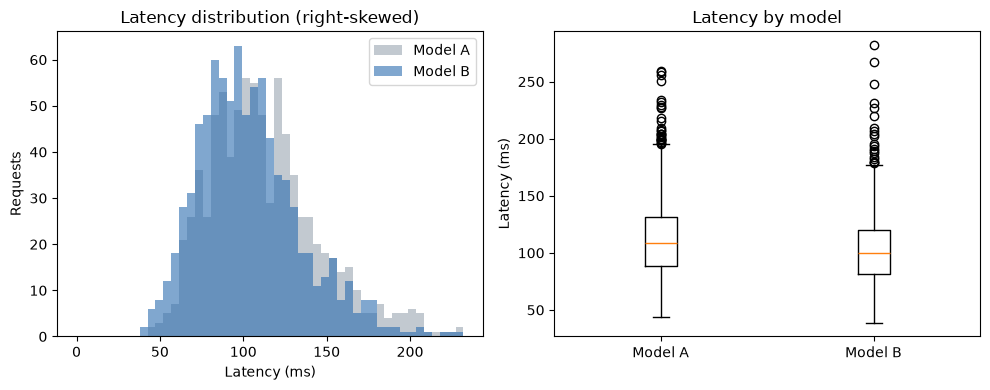

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
bins = np.linspace(0, df["latency_ms"].quantile(0.995), 50)
axes[0].hist(lat_a, bins=bins, alpha=0.6, label="Model A", color="#9aa5b1")
axes[0].hist(lat_b, bins=bins, alpha=0.6, label="Model B", color="#2b6cb0")
axes[0].set_xlabel("Latency (ms)")
axes[0].set_ylabel("Requests")
axes[0].set_title("Latency distribution (right-skewed)")
axes[0].legend()
axes[1].boxplot([lat_a, lat_b], tick_labels=["Model A", "Model B"])
axes[1].set_ylabel("Latency (ms)")
axes[1].set_title("Latency by model")
plt.tight_layout()
plt.savefig(PLOTS / "model_latency.png", dpi=120)
plt.show()

## 6. Two metrics, one decision: Holm correction

Testing two metrics gives two chances of a false positive. The Holm procedure adjusts the p-values so that the chance of *any* false positive across the family stays at 5%. We use the Welch p-value for latency (pre-specified), not whichever latency test happens to look better.

In [11]:
raw = {"accuracy": r_acc.p_value, "latency (Welch)": r_lat.welch_p}
adj = holm(list(raw.values()))
pd.DataFrame({"raw p": list(raw.values()), "Holm-adjusted p": adj}, index=raw.keys()).map(lambda v: f"{v:.2g}")

,raw p,Holm-adjusted p
accuracy,0.0041,0.0041
latency (Welch),6e-09,1.2e-08


## 7. Why we analyse once: the cost of peeking

The sample size above assumes one analysis at the end. A tempting alternative is to check the dashboard every day and stop as soon as p < 0.05. The simulation below runs thousands of **A/A tests** (both arms have identical 85% accuracy, so any "significant" result is a false positive) and stops at the first significant look.

 looks at the data  false positive rate
                 1                0.051
                 2                0.087
                 5                0.143
                10                0.187
                20                0.247


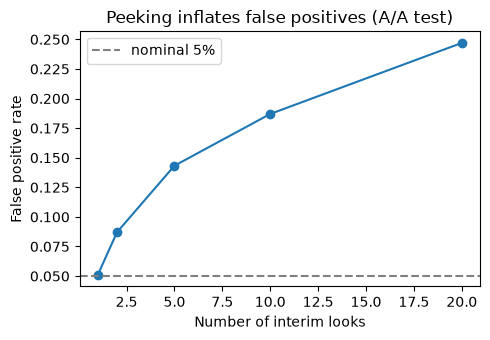

In [12]:
looks = [1, 2, 5, 10, 20]
fpr = [peeking_false_positive_rate(n_per_group, k, p=0.85, alpha=0.05, n_sims=4000, seed=1) for k in looks]
print(pd.DataFrame({"looks at the data": looks, "false positive rate": np.round(fpr, 3)}).to_string(index=False))

plt.figure(figsize=(5, 3.5))
plt.plot(looks, fpr, marker="o")
plt.axhline(0.05, ls="--", c="grey", label="nominal 5%")
plt.xlabel("Number of interim looks")
plt.ylabel("False positive rate")
plt.title("Peeking inflates false positives (A/A test)")
plt.legend()
plt.tight_layout()
plt.savefig(PLOTS / "peeking.png", dpi=120)
plt.show()

If you genuinely need to monitor a test while it runs, use a method designed for it (group-sequential boundaries such as O'Brien-Fleming, or always-valid / sequential tests), not repeated fixed-horizon tests.

## 8. Conclusion

All numbers below are printed by the cells above.

- **Peeking.** In A/A simulations, stopping at the first p < 0.05 across 10 looks gave a 19% false positive rate instead of 5%.
- **Design.** Detecting a 5-point accuracy gain (85% → 90%) with 80% power at α = 0.025 per metric needs 824 requests per model. We planned 1,700 requests in total and analysed once.
- **Randomisation looked healthy** (no sample ratio mismatch).
- **Accuracy.** Model B was more accurate: 90.7% vs 86.3%, a gain of +4.4 percentage points (95% CI +1.4 to +7.5, p = 0.004, Holm-adjusted p = 0.004). The interval excludes zero but is wide, so the size of the gain is uncertain. Note that the gain *built into* the simulation is 7 points; the observed +4.4 is an under-estimate by chance, and the interval still covers the truth. This is why the interval matters more than the point estimate.
- **Latency.** Model B was faster: mean −9.5 ms (95% CI −12.7 to −6.3, Welch p < 0.001) and median −9.0 ms (bootstrap CI −12.7 to −5.7). The effect is moderate rather than dramatic: a random B request is faster than a random A request 58% of the time.
- **Decision.** On this evidence, B is the better candidate on both metrics. A real rollout would also check high-percentile latency (p95/p99), error rates and stability over time, and could ramp traffic gradually.

**What this does not show.** The data is simulated with B built to be better, so these results only demonstrate that the procedure recovers a known effect. They say nothing about any real model. Point the same functions at real prediction logs to make a real decision. A non-significant result would *not* have shown the models are equal. It would only mean the test could not distinguish them, and the confidence interval would show how large a difference is still plausible.